# Example of the `aitlas` toolbox in the context of image segmentation

This notebook shows a sample implementation of a image segmentation using the `aitlas` toolbox.

## Import the required packages

In [ ]:
from aitlas.datasets import AIRSDataset
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
from aitlas.utils import image_loader

## Visualize images and masks

Total number of patches: 47900


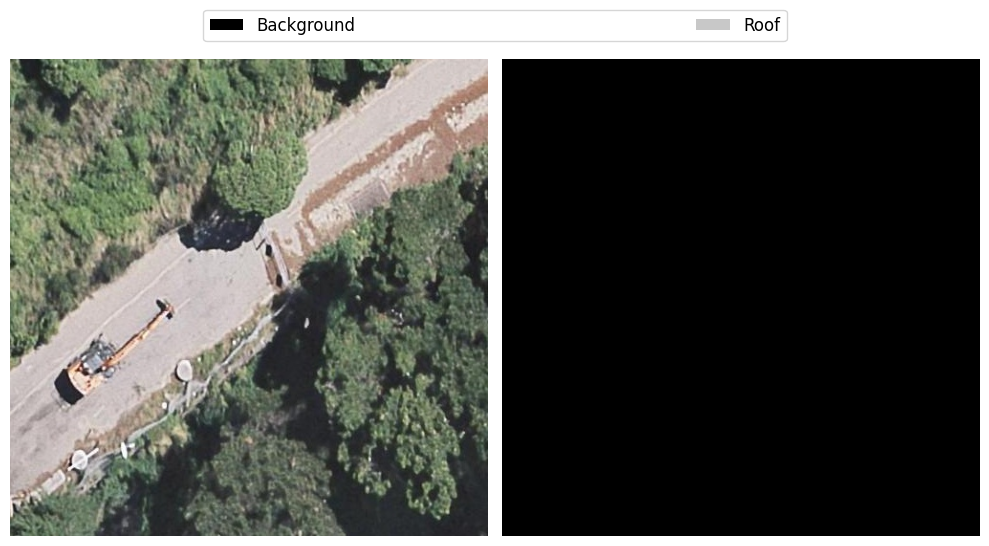

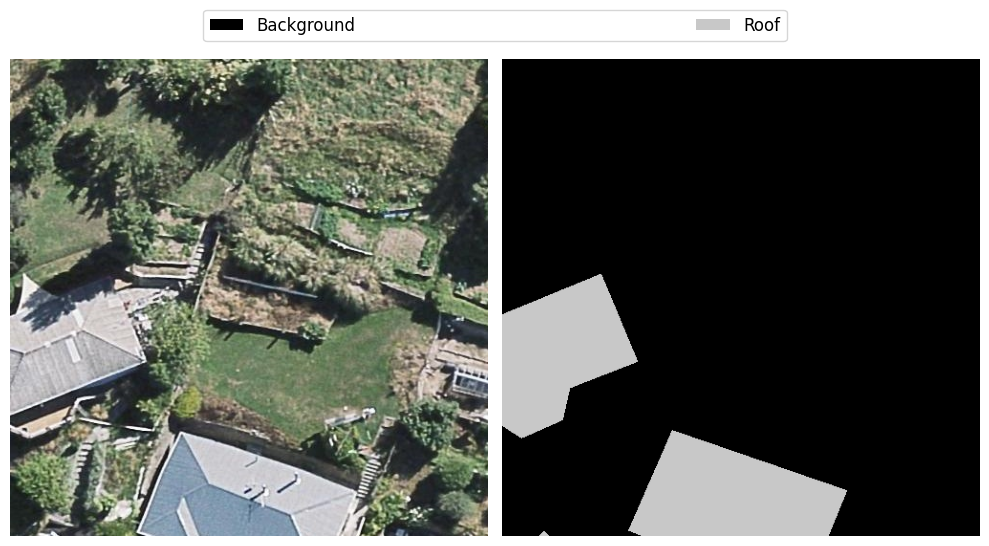

In [11]:
dataset_config = {
    "data_dir": "/home/dragik/data/Airs/train/data/", 
    "csv_file": "/home/dragik/data/Airs/train/train.txt"
    }
dataset = AIRSDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1567)
dataset.show_image(1000);

## Load train data

In [4]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/Airs/train/data/", 
    "csv_file": "/home/dragik/data/Airs/train/train.txt",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose"],
    "target_transforms": ["aitlas.transforms.Transpose"],
}
train_dataset = AIRSDataset(train_dataset_config)
len(train_dataset)

47900

## Create the model

In [5]:
epochs = 5
model_directory = "/home/dragik/data/experiments/airs"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "threshold": 0.5,
    "metrics": ["iou"],
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [19]:
model.train_model(
    train_dataset=train_dataset, 
    epochs=epochs, 
    model_directory=model_directory, 
    run_id="1"
)

2026-08-19 12:36:05,246 INFO Starting training.
training: 100%|██████████| 5988/5988 [35:45<00:00,  2.79it/s]
2026-08-19 13:11:50,648 INFO epoch: 1, time: 2145, loss:  0.02458
testing on train set: 100%|██████████| 5988/5988 [11:41<00:00,  8.54it/s]
2026-08-19 13:23:33,598 INFO IOU:0.989686434176709, IOU mean:0.8745598734967487, IOU per Class:[0.99472219 0.75439755]
training: 100%|██████████| 5988/5988 [35:42<00:00,  2.79it/s]
2026-08-19 13:59:16,517 INFO epoch: 2, time: 2143, loss:  0.00567
testing on train set: 100%|██████████| 5988/5988 [11:33<00:00,  8.64it/s]
2026-08-19 14:10:49,562 INFO IOU:0.9878675981800429, IOU mean:0.86831068995385, IOU per Class:[0.99380726 0.74281412]
training: 100%|██████████| 5988/5988 [35:50<00:00,  2.78it/s]
2026-08-19 14:46:39,682 INFO epoch: 3, time: 2150, loss:  0.00446
testing on train set: 100%|██████████| 5988/5988 [11:40<00:00,  8.54it/s]
2026-08-19 14:58:20,469 INFO IOU:0.9918347024827919, IOU mean:0.901129678182169, IOU per Class:[0.99581784 0.

0.00365788452311697

## Evalute the model using test data

In [7]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/Airs/test/images/", 
    "csv_file": "/home/dragik/data/Airs/test/test_list.txt",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose"],
    "target_transforms": ["aitlas.transforms.Transpose"],
}

test_dataset = AIRSDataset(test_dataset_config)
len(test_dataset)

model = DeepLabV3(model_config)
model.prepare()
model_path = "/home/dragik/data/experiments/airs/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(["iou"])

2026-08-20 06:37:48,860 INFO Loading checkpoint /home/dragik/data/experiments/airs/checkpoint.pth.tar
2026-08-20 06:37:49,386 INFO Loaded checkpoint /home/dragik/data/experiments/airs/checkpoint.pth.tar at epoch 6
testing on test set: 100%|██████████| 2375/2375 [15:53<00:00,  2.49it/s]


[{'IOU': 0.9733137256392618,
  'IOU mean': 0.9047282373850605,
  'IOU per Class': array([0.98555054, 0.82390594])}]

## Predictions

2026-08-21 08:31:06,552 INFO Loading checkpoint /home/dragik/data/experiments/airs/checkpoint.pth.tar
2026-08-21 08:31:06,926 INFO Loaded checkpoint /home/dragik/data/experiments/airs/checkpoint.pth.tar at epoch 6


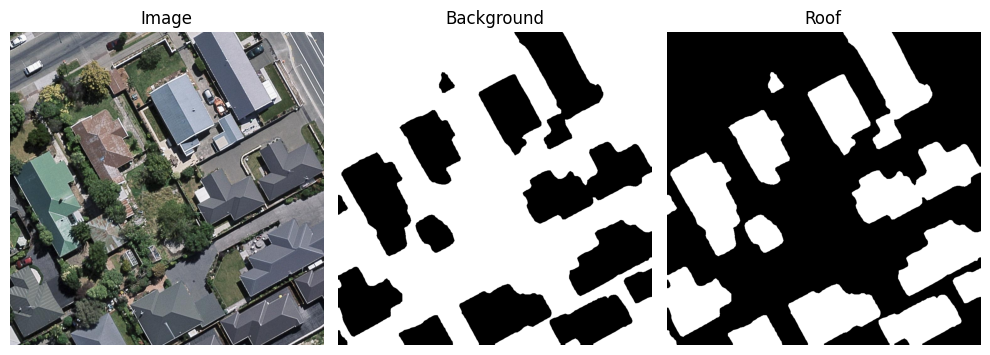

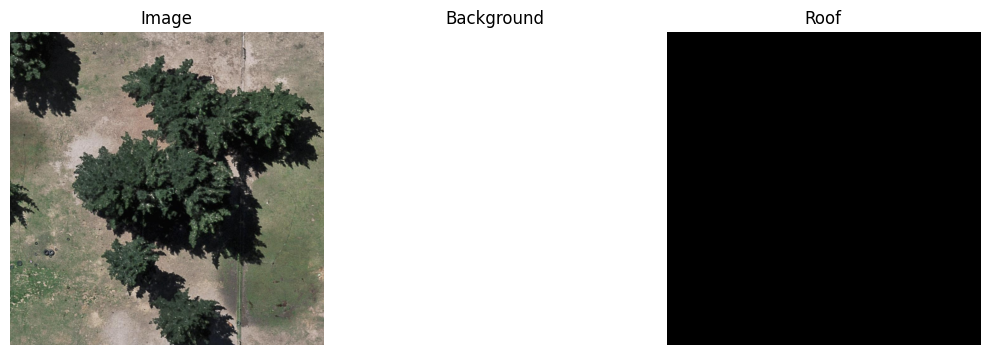

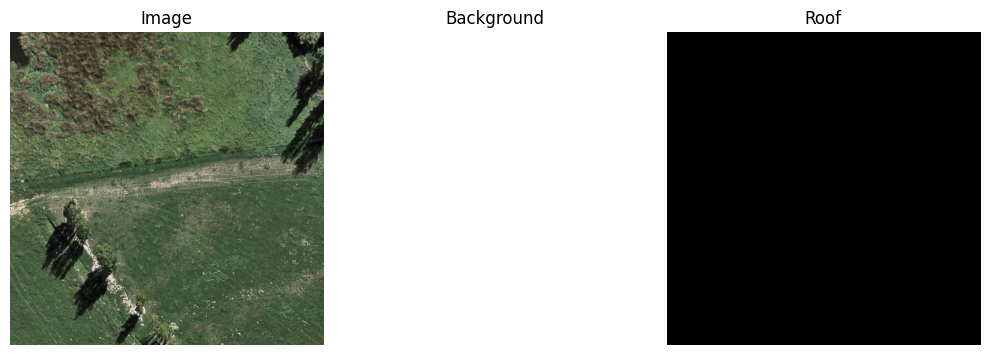

In [8]:
model_path = "/home/dragik/data/experiments/airs/checkpoint.pth.tar"
labels = ["Background", "Roof"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader("/home/dragik/data/Airs/test/images/christchurch_687_14.jpg")
fig = model.predict_masks(image, labels, transform)

image = image_loader("/home/dragik/data/Airs/test/images/christchurch_15_49.jpg")
fig = model.predict_masks(image, labels, transform)

image = image_loader("/home/dragik/data/Airs/test/images/christchurch_460_26.jpg")
fig = model.predict_masks(image, labels, transform)